# Overview

The purpose of this notebook is to explore the neww addtional data that will be use to expand the household data across Miami dataset

In [4]:
# Load the datasets

import pandas as pd

from pathlib import Path

# Support running the notebook with either the repository root or notebooks/ as cwd.
DATA_DIR_CANDIDATES = (Path.cwd() / "data", Path.cwd().parent / "data")
DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if path.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find the project's data directory. Run this notebook from the repository root or notebooks/."
    )

RAW_DATA_DIR = DATA_DIR / "raw"
CLEANED_DATA_DIR = DATA_DIR / "cleaned"
CLEANED_DATA_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "home-values": RAW_DATA_DIR / "Zip_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv",
    "rental": RAW_DATA_DIR / "Zip_zori_uc_sfrcondomfr_sm_month.csv",
}
OUTPUT_DATASETS = {
    "home-values": CLEANED_DATA_DIR / "Miami_home_values.csv",
    "rental": CLEANED_DATA_DIR / "Miami_rental_values.csv",
}
for name, source_path in DATASETS.items():
    source_df = pd.read_csv(source_path)
    miami_df = source_df.loc[
        (source_df["City"] == "Miami") & (source_df["State"] == "FL")
    ].copy()
    miami_df.to_csv(OUTPUT_DATASETS[name], index=False)

# Remove monthly price columns dated from 2000 through 2024, inclusive.
for name, output_path in OUTPUT_DATASETS.items():
    filtered_df = pd.read_csv(output_path)
    price_columns_to_drop = [
        column
        for column in filtered_df.columns
        if column[:4].isdigit() and 2000 <= int(column[:4]) <= 2025
    ]
    filtered_df.drop(columns=price_columns_to_drop).to_csv(output_path, index=False)

# Reload the saved files and display the requested details.
filtered_datasets = {
    name: pd.read_csv(path)
    for name, path in OUTPUT_DATASETS.items()
}

for name, filtered_df in filtered_datasets.items():
    print(f"{name}: {OUTPUT_DATASETS[name].name}")
    print("Column names:")
    print(filtered_df.columns.tolist())
    print("Head:")
    display(filtered_df.head())
    print(f"Shape: {filtered_df.shape}")
    print()

home-values: Miami_home_values.csv
Column names:
['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName', 'State', 'City', 'Metro', 'CountyName', '2026-01-31', '2026-02-28', '2026-03-31', '2026-04-30', '2026-05-31', '2026-06-30', '2026-07-31', '2026-08-31']
Head:


,RegionID,SizeRank,RegionName,RegionType,StateName,State,City,Metro,CountyName,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31
0,72479,532,33177,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,572001.396142,572600.659570,572768.260095,572439.143081,572045.092820,571413.658941,571333.660763,571878.857601
1,72428,719,33125,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,458810.786391,458821.311976,459090.730605,458379.150299,457880.575590,458152.983552,459977.688607,462144.109086
2,72478,911,33176,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,619516.277251,621550.059900,623094.569954,623496.917427,623603.630863,623471.991293,624095.640402,625867.558301
3,72468,1012,33165,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,673162.864323,674929.075867,676156.501777,676094.916531,676228.455622,676771.339057,678472.560963,680797.179702
4,72494,1186,33193,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,442355.664123,441797.636349,441521.148034,441183.154906,441067.989391,441041.959003,441580.978071,442117.321392


Shape: (30, 17)

rental: Miami_rental_values.csv
Column names:
['RegionID', 'SizeRank', 'RegionName', 'RegionType', 'StateName', 'State', 'City', 'Metro', 'CountyName', '2026-01-31', '2026-02-28', '2026-03-31', '2026-04-30', '2026-05-31', '2026-06-30', '2026-07-31', '2026-08-31']
Head:


,RegionID,SizeRank,RegionName,RegionType,StateName,State,City,Metro,CountyName,2026-01-31,2026-02-28,2026-03-31,2026-04-30,2026-05-31,2026-06-30,2026-07-31,2026-08-31
0,72479,532,33177,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,2773.309455,2774.921234,2810.792150,2853.532707,2873.582158,2831.216533,2837.589671,2818.554226
1,72428,719,33125,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,2329.948258,2343.501323,2338.540953,2343.803702,2367.529247,2359.229336,2372.197132,2379.843835
2,72478,911,33176,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,2247.329050,2237.606074,2271.559104,2252.734700,2264.678650,2275.870591,2309.894964,2303.963816
3,72468,1012,33165,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,3350.049412,3278.916322,3243.497895,3190.257233,3174.586655,3179.622522,3289.030200,3247.500000
4,72494,1186,33193,zip,FL,FL,Miami,"Miami-Fort Lauderdale-Pompano Beach, FL",Miami-Dade County,2382.909949,2362.085749,2324.695703,2319.349149,2319.952724,2359.771817,2372.358258,2374.074074


Shape: (29, 17)



For every recommended ZIP, show:
1. Typical rent
2. Difference from the user’s budget
3. Estimated commute
4. Nearby transit options
5. Rent trend
6. Flood-risk information
7. Explanation of why it was recommended

Question to the person
1. Should we include transportation and flood risk information for the recommendation engine 
2. Does 

# Explore the Miami Transit Data

Understand how the data pattern wrks and how we can improve it 

In [11]:
# Load the Miami-Dade transit dataset while preserving ZIP codes as strings.
from pathlib import Path

DATA_DIR_CANDIDATES = (Path.cwd() / "data", Path.cwd().parent / "data")
DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if path.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find the project's data directory. "
        "Run this notebook from the repository root or notebooks/."
    )

TRANSIT_PATH = DATA_DIR / "raw" / "google_transit" / "miami_transit.csv"
miami_transit = pd.read_csv(TRANSIT_PATH, dtype={"zip_code": "string"})

print(f"Dataset: {TRANSIT_PATH.name}")
print(f"Shape: {miami_transit.shape}")
print()

Dataset: miami_transit.csv
Shape: (78, 21)



In [10]:
print("Column names:")
print(miami_transit.columns.tolist())
print(f"Number of columns: {miami_transit.shape[1]}")
print()

print("First five rows:")
display(miami_transit.head(20))
print()

print("Data types:")
display(miami_transit.dtypes.rename("dtype").to_frame())
print()

missing_summary = pd.DataFrame({
    "missing_count": miami_transit.isna().sum(),
    "missing_percent": (miami_transit.isna().mean() * 100).round(2),
})

print("Missing values by column:")
display(missing_summary)

print("Columns with missing values:")
columns_with_missing = missing_summary.loc[
    missing_summary["missing_count"] > 0
]
if columns_with_missing.empty:
    print("No columns contain missing values.")
else:
    display(columns_with_missing)

print("Descriptive statistics:")
display(miami_transit.describe(include="all").T)


Column names:
['zip_code', 'transit_stop_count', 'unique_route_count', 'transit_types', 'bus_route_count', 'metrorail_route_count', 'metromover_route_count', 'morning_peak_departures', 'evening_peak_departures', 'accessible_stop_share', 'wheelchair_accessible_trip_share', 'bike_allowed_trip_share', 'gtfs_agency', 'service_start_date', 'service_end_date', 'data_as_of']
Number of columns: 16

First five rows:


,zip_code,transit_stop_count,unique_route_count,transit_types,bus_route_count,metrorail_route_count,metromover_route_count,morning_peak_departures,evening_peak_departures,accessible_stop_share,wheelchair_accessible_trip_share,bike_allowed_trip_share,gtfs_agency,service_start_date,service_end_date,data_as_of
0,33010,157,12,bus|metrorail,11,1,0,843,1258,0.0,0.741091,0.741091,Miami-Dade Transit,20210101,20271231,2026-10-27
1,33012,149,6,bus,6,0,0,769,1146,0.0,0.817755,0.817755,Miami-Dade Transit,20210101,20271231,2026-10-27
2,33013,88,7,bus,7,0,0,479,695,0.0,0.603163,0.603163,Miami-Dade Transit,20210101,20271231,2026-10-27
3,33014,66,6,bus,6,0,0,304,469,0.0,0.979630,0.979630,Miami-Dade Transit,20210101,20271231,2026-10-27
4,33015,54,6,bus,6,0,0,273,421,0.0,1.000000,1.000000,Miami-Dade Transit,20210101,20271231,2026-10-27
5,33016,78,4,bus,4,0,0,264,377,0.0,0.600625,0.600625,Miami-Dade Transit,20210101,20271231,2026-10-27
6,33018,41,3,bus,3,0,0,131,197,0.0,0.149077,0.149077,Miami-Dade Transit,20210101,20271231,2026-10-27
7,33030,106,9,bus,9,0,0,429,632,0.0,0.877034,0.877034,Miami-Dade Transit,20210101,20271231,2026-10-27
8,33031,1,1,bus,1,0,0,2,3,0.0,1.000000,1.000000,Miami-Dade Transit,20210101,20271231,2026-10-27
9,33032,96,5,bus,5,0,0,513,808,0.0,0.997490,0.997490,Miami-Dade Transit,20210101,20271231,2026-10-27



Data types:


,dtype
zip_code,string[python]
transit_stop_count,int64
unique_route_count,int64
transit_types,object
bus_route_count,int64
metrorail_route_count,int64
metromover_route_count,int64
morning_peak_departures,int64
evening_peak_departures,int64
accessible_stop_share,float64



Missing values by column:


,missing_count,missing_percent
zip_code,0,0.0
transit_stop_count,0,0.0
unique_route_count,0,0.0
transit_types,0,0.0
bus_route_count,0,0.0
metrorail_route_count,0,0.0
metromover_route_count,0,0.0
morning_peak_departures,0,0.0
evening_peak_departures,0,0.0
accessible_stop_share,0,0.0


Columns with missing values:
No columns contain missing values.
Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
zip_code,78,78,33010,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transit_stop_count,78.0,NaN,NaN,NaN,89.051282,54.12969,1.0,48.5,88.0,120.0,251.0
unique_route_count,78.0,NaN,NaN,NaN,8.820513,5.445703,1.0,6.0,8.0,12.0,28.0
transit_types,78,4,bus,62,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bus_route_count,78.0,NaN,NaN,NaN,8.538462,5.031569,1.0,6.0,8.0,11.0,26.0
metrorail_route_count,78.0,NaN,NaN,NaN,0.179487,0.386244,0.0,0.0,0.0,0.0,1.0
metromover_route_count,78.0,NaN,NaN,NaN,0.102564,0.413718,0.0,0.0,0.0,0.0,2.0
morning_peak_departures,78.0,NaN,NaN,NaN,614.397436,418.275071,2.0,348.25,554.0,857.0,2029.0
evening_peak_departures,78.0,NaN,NaN,NaN,935.217949,646.961723,3.0,510.0,809.0,1294.25,3133.0
accessible_stop_share,78.0,NaN,NaN,NaN,0.000135,0.001192,0.0,0.0,0.0,0.0,0.010526


# Explore the Miami Rental Market Data

This section profiles the merged ZIP-level ZORI and HUD rental-market dataset.


In [12]:
# Load the merged Miami rental-market dataset while preserving ZIP codes as strings.
from pathlib import Path
import pandas as pd

DATA_DIR_CANDIDATES = (Path.cwd() / "data", Path.cwd().parent / "data")
DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if path.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find the project data directory.")

RENTAL_MARKET_PATH = DATA_DIR / "cleaned" / "Rental-Market.csv"
rental_market = pd.read_csv(RENTAL_MARKET_PATH, dtype={"zip_code": "string"})

print(f"Dataset: {RENTAL_MARKET_PATH.name}")
print(f"Shape: {rental_market.shape}")


Dataset: Rental-Market.csv
Shape: (84, 17)


In [13]:
print("Column names:")
print(rental_market.columns.tolist())
print(f"Number of columns: {rental_market.shape[1]}")

print("First five rows:")
display(rental_market.head())

print("Data types:")
display(rental_market.dtypes.rename("dtype").to_frame())

missing_summary = pd.DataFrame({
    "missing_count": rental_market.isna().sum(),
    "missing_percent": (rental_market.isna().mean() * 100).round(2),
})
print("Missing-value summary:")
display(missing_summary)

print("Columns with missing values:")
columns_with_missing = missing_summary.loc[missing_summary["missing_count"] > 0]
if columns_with_missing.empty:
    print("No columns contain missing values.")
else:
    display(columns_with_missing)

print("Descriptive statistics:")
display(rental_market.describe(include="all").T)


Column names:
['zip_code', 'zori_2026_01', 'zori_2026_02', 'zori_2026_03', 'zori_2026_04', 'zori_2026_05', 'zori_2026_06', 'zori_2026_07', 'zori_2026_08', 'zori_latest_rent', 'hud_efficiency', 'hud_1_bedroom', 'hud_2_bedroom', 'hud_3_bedroom', 'hud_4_bedroom', 'zori_source', 'hud_source']
Number of columns: 17
First five rows:


,zip_code,zori_2026_01,zori_2026_02,zori_2026_03,zori_2026_04,zori_2026_05,zori_2026_06,zori_2026_07,zori_2026_08,zori_latest_rent,hud_efficiency,hud_1_bedroom,hud_2_bedroom,hud_3_bedroom,hud_4_bedroom,zori_source,hud_source
0,33010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1720,1870,2260,2890,3300,NaN,HUD Small Area Fair Market Rents
1,33012,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1910,2080,2510,3210,3670,NaN,HUD Small Area Fair Market Rents
2,33013,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1730,1880,2270,2900,3320,NaN,HUD Small Area Fair Market Rents
3,33014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2060,2230,2700,3450,3950,NaN,HUD Small Area Fair Market Rents
4,33015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2180,2370,2860,3660,4180,NaN,HUD Small Area Fair Market Rents


Data types:


,dtype
zip_code,string[python]
zori_2026_01,float64
zori_2026_02,float64
zori_2026_03,float64
zori_2026_04,float64
zori_2026_05,float64
zori_2026_06,float64
zori_2026_07,float64
zori_2026_08,float64
zori_latest_rent,float64


Missing-value summary:


,missing_count,missing_percent
zip_code,0,0.00
zori_2026_01,56,66.67
zori_2026_02,56,66.67
zori_2026_03,55,65.48
zori_2026_04,55,65.48
zori_2026_05,55,65.48
zori_2026_06,55,65.48
zori_2026_07,55,65.48
zori_2026_08,55,65.48
zori_latest_rent,55,65.48


Columns with missing values:


,missing_count,missing_percent
zori_2026_01,56,66.67
zori_2026_02,56,66.67
zori_2026_03,55,65.48
zori_2026_04,55,65.48
zori_2026_05,55,65.48
zori_2026_06,55,65.48
zori_2026_07,55,65.48
zori_2026_08,55,65.48
zori_latest_rent,55,65.48
zori_source,55,65.48


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
zip_code,84,84,33010,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
zori_2026_01,28.0,NaN,NaN,NaN,2808.393565,484.297892,2122.036267,2428.757616,2684.581859,3291.765836,3856.182758
zori_2026_02,28.0,NaN,NaN,NaN,2815.328313,484.831759,2137.60944,2431.364211,2677.49771,3277.22152,3866.957877
zori_2026_03,29.0,NaN,NaN,NaN,2824.940432,480.865278,2107.030074,2453.794389,2722.983826,3243.497895,3846.303678
zori_2026_04,29.0,NaN,NaN,NaN,2836.546122,485.128576,2100.077129,2462.111969,2731.433534,3190.257233,3859.062284
zori_2026_05,29.0,NaN,NaN,NaN,2838.32459,492.24909,2097.444334,2384.495322,2765.197526,3174.586655,3834.779849
zori_2026_06,29.0,NaN,NaN,NaN,2837.688464,491.790093,2106.902143,2376.798407,2744.2437,3179.622522,3831.772434
zori_2026_07,29.0,NaN,NaN,NaN,2850.054517,486.158263,2127.589713,2407.033392,2768.770342,3289.0302,3813.44959
zori_2026_08,29.0,NaN,NaN,NaN,2857.159062,483.033805,2079.871969,2459.888889,2735.655983,3247.5,3831.361774
zori_latest_rent,29.0,NaN,NaN,NaN,2857.159062,483.033805,2079.871969,2459.888889,2735.655983,3247.5,3831.361774


# Explore Miami Rent Trends

This section profiles historical Zillow ZORI observations and the derived ZIP-level rent trend features.

In [16]:
from pathlib import Path
import pandas as pd

DATA_DIR_CANDIDATES = (Path.cwd() / "data", Path.cwd().parent / "data")
DATA_DIR = next((path for path in DATA_DIR_CANDIDATES if path.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Could not find the project data directory.")

ZORI_HISTORY_PATH = DATA_DIR / "cleaned" / "zori_history.csv"
RENT_TRENDS_PATH = DATA_DIR / "cleaned" / "rent-trends.csv"
zori_history = pd.read_csv(
    ZORI_HISTORY_PATH,
    dtype={"zip_code": "string"},
)
rent_trends = pd.read_csv(RENT_TRENDS_PATH, dtype={"zip_code": "string"})

print(f"Historical dataset: {ZORI_HISTORY_PATH.name}")
print(f"Historical shape: {zori_history.shape}")
print(f"Trend dataset: {RENT_TRENDS_PATH.name}")
print(f"Trend shape: {rent_trends.shape}")

Historical dataset: zori_history.csv
Historical shape: (6021, 5)
Trend dataset: rent-trends.csv
Trend shape: (74, 9)


In [18]:
print("Historical columns:")
print(zori_history.columns.tolist())
print("\nTrend columns:")
print(rent_trends.columns.tolist())

print("\nHistorical sample:")
display(zori_history.head())
print("Trend sample:")
display(rent_trends.head())

print("Historical data types:")
display(zori_history.dtypes.rename("dtype").to_frame())
print("Trend data types:")
display(rent_trends.dtypes.rename("dtype").to_frame())

Historical columns:
['zip_code', 'observation_month', 'zori_rent_usd', 'source', 'source_date']

Trend columns:
['zip_code', 'latest_rent_usd', 'rent_3_month_change_pct', 'rent_12_month_change_pct', 'rent_24_month_change_pct', 'rent_volatility', 'rent_direction', 'source', 'source_date']

Historical sample:


,zip_code,observation_month,zori_rent_usd,source,source_date
0,33010,2024-01,1994.893757,Zillow ZORI,2024-01
1,33010,2024-02,2013.329465,Zillow ZORI,2024-02
2,33010,2024-03,1972.299464,Zillow ZORI,2024-03
3,33010,2024-04,1969.312846,Zillow ZORI,2024-04
4,33010,2024-05,1960.497136,Zillow ZORI,2024-05


Trend sample:


,zip_code,latest_rent_usd,rent_3_month_change_pct,rent_12_month_change_pct,rent_24_month_change_pct,rent_volatility,rent_direction,source,source_date
0,33010,2062.500000,4.484514,2.049527,3.844901,1.936998,increasing,Zillow ZORI,2026-08
1,33012,2200.865530,0.607224,0.365369,1.517011,0.942041,stable,Zillow ZORI,2026-08
2,33013,2524.444444,2.403093,-0.263742,NaN,2.341946,increasing,Zillow ZORI,2026-08
3,33014,2362.098214,0.642410,0.425908,0.864864,0.665593,stable,Zillow ZORI,2026-08
4,33015,2253.298920,0.354426,-1.320073,-0.359294,0.876467,stable,Zillow ZORI,2026-08


Historical data types:


,dtype
zip_code,string[python]
observation_month,object
zori_rent_usd,float64
source,object
source_date,object


Trend data types:


,dtype
zip_code,string[python]
latest_rent_usd,float64
rent_3_month_change_pct,float64
rent_12_month_change_pct,float64
rent_24_month_change_pct,float64
rent_volatility,float64
rent_direction,object
source,object
source_date,object


In [19]:
print("Missing values in historical data:")
history_missing = pd.DataFrame({
    "missing_count": zori_history.isna().sum(),
    "missing_percent": (zori_history.isna().mean() * 100).round(2),
})
display(history_missing)

print("Missing values in trend data:")
trend_missing = pd.DataFrame({
    "missing_count": rent_trends.isna().sum(),
    "missing_percent": (rent_trends.isna().mean() * 100).round(2),
})
display(trend_missing)

print("Duplicate historical ZIP/month rows:", zori_history.duplicated(["zip_code", "observation_month"]).sum())
print("Duplicate trend ZIP rows:", rent_trends["zip_code"].duplicated().sum())

Missing values in historical data:


,missing_count,missing_percent
zip_code,0,0.0
observation_month,0,0.0
zori_rent_usd,0,0.0
source,0,0.0
source_date,0,0.0


Missing values in trend data:


,missing_count,missing_percent
zip_code,0,0.00
latest_rent_usd,0,0.00
rent_3_month_change_pct,0,0.00
rent_12_month_change_pct,4,5.41
rent_24_month_change_pct,8,10.81
rent_volatility,4,5.41
rent_direction,0,0.00
source,0,0.00
source_date,0,0.00


Duplicate historical ZIP/month rows: 0
Duplicate trend ZIP rows: 0


In [20]:
zori_history["observation_month"] = pd.to_datetime(zori_history["observation_month"])
trend_features = [
    "latest_rent_usd",
    "rent_3_month_change_pct",
    "rent_12_month_change_pct",
    "rent_24_month_change_pct",
    "rent_volatility",
]
print("Historical coverage:")
print(zori_history["observation_month"].agg(["min", "max", "nunique"]))
print("ZIP coverage:", zori_history["zip_code"].nunique())
print("Trend descriptive statistics:")
display(rent_trends[trend_features].describe().T)
print("Rent direction counts:")
display(rent_trends["rent_direction"].value_counts(dropna=False).rename("zip_count").to_frame())

Historical coverage:
min        2015-01-01 00:00:00
max        2026-08-01 00:00:00
nunique                    140
Name: observation_month, dtype: object
ZIP coverage: 74
Trend descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
latest_rent_usd,74.0,2817.263804,722.147531,2062.500000,2376.622289,2661.652958,2986.303105,7161.927609
rent_3_month_change_pct,74.0,0.852271,2.021586,-4.203373,-0.473239,0.699483,2.101906,6.899490
rent_12_month_change_pct,70.0,1.299879,2.257379,-2.650460,-0.057307,0.806629,2.346901,8.558722
rent_24_month_change_pct,66.0,2.186263,3.874457,-5.222038,0.054882,1.544480,4.237030,22.552969
rent_volatility,70.0,1.139191,0.623766,0.328840,0.731159,0.959667,1.322258,3.176877


Rent direction counts:


,zip_count
rent_direction,
increasing,36
stable,25
decreasing,13


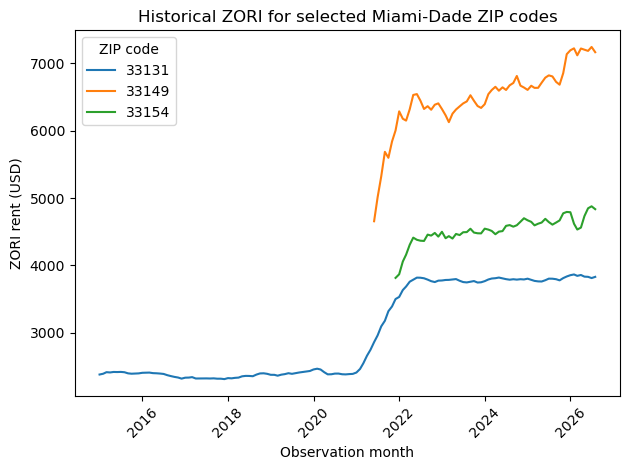

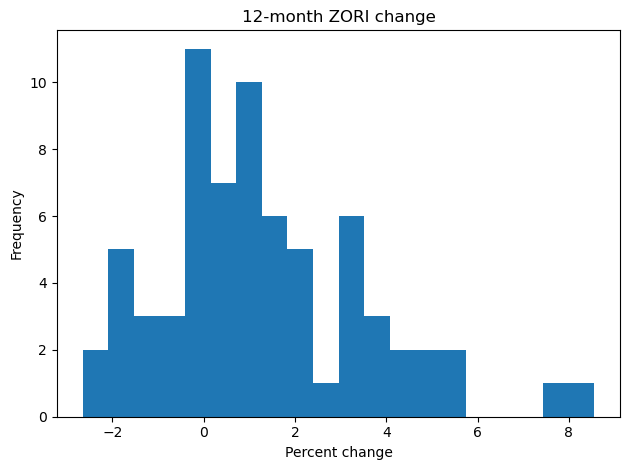

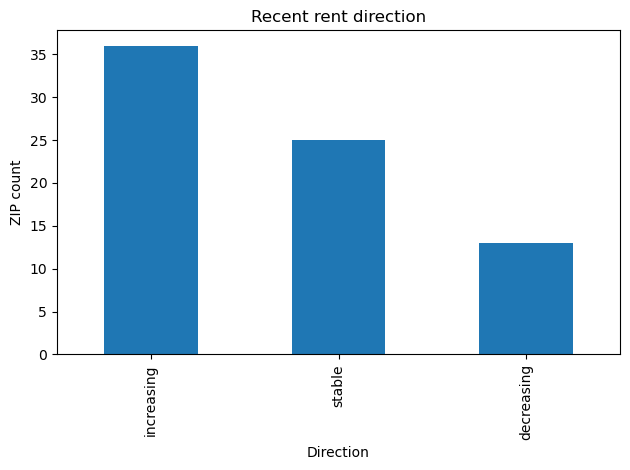

In [21]:
import matplotlib.pyplot as plt

selected_zips = rent_trends.nlargest(3, "latest_rent_usd")["zip_code"].tolist()
plot_data = zori_history[zori_history["zip_code"].isin(selected_zips)]
for zip_code, group in plot_data.groupby("zip_code"):
    plt.plot(group["observation_month"], group["zori_rent_usd"], label=zip_code)
plt.title("Historical ZORI for selected Miami-Dade ZIP codes")
plt.xlabel("Observation month")
plt.ylabel("ZORI rent (USD)")
plt.legend(title="ZIP code")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

rent_trends["rent_12_month_change_pct"].dropna().plot(kind="hist", bins=20, title="12-month ZORI change")
plt.xlabel("Percent change")
plt.tight_layout()
plt.show()

rent_trends["rent_direction"].value_counts().plot(kind="bar", title="Recent rent direction")
plt.xlabel("Direction")
plt.ylabel("ZIP count")
plt.tight_layout()
plt.show()